In [ ]:
%pip install "semanticlens-vision @ git+https://github.com/semanticClimate/semanticlens.git"


In [1]:
import importlib.metadata

print("Installed:", importlib.metadata.version("semanticlens-vision"))


Installed: 0.1.0a1


In [3]:
from pathlib import Path
import ipywidgets as widgets
import pypdfium2 as pdfium
from IPython.display import display, clear_output

pdf_path = None

uploader = widgets.FileUpload(
    accept=".pdf",
    multiple=False,
    description="Upload PDF",
)

output = widgets.Output()

def handle_upload(change):
    global pdf_path

    value = change["new"]
    if not value:
        return

    with output:
        clear_output(wait=True)

        try:
            # Support ipywidgets 7 and 8
            if isinstance(value, dict):
                filename, file_info = next(iter(value.items()))
            else:
                file_info = value[0]
                filename = file_info["name"]

            filename = Path(filename).name

            if not filename.lower().endswith(".pdf"):
                raise ValueError("Only PDF files are supported.")

            upload_dir = Path.cwd() / "pdf_uploads"
            upload_dir.mkdir(parents=True, exist_ok=True)

            path = upload_dir / filename
            path.write_bytes(bytes(file_info["content"]))

            with pdfium.PdfDocument(str(path)) as pdf:
                page_count = len(pdf)

            if page_count == 0:
                raise ValueError("PDF has no pages.")

            pdf_path = path

            print("✅ PDF uploaded successfully!")
            print("Filename:", pdf_path.name)
            print("Pages:", page_count)
            print("Path:", pdf_path)

        except Exception as exc:
            print(f"❌ {type(exc).__name__}: {exc}")

uploader.observe(handle_upload, names="value")

display(uploader, output)


FileUpload(value={}, accept='.pdf', description='Upload PDF')

Output()

In [4]:
from pathlib import Path
from semanticlens import PipelineConfig

# Shared workspace for all SemanticLens modules
workspace = (Path.cwd() / "lens_data").resolve()
workspace.mkdir(parents=True, exist_ok=True)

# Core pipeline configuration
pipeline_config = PipelineConfig(
    workspace=workspace,
    batch_size=1,
    default_top_k=3,
)

print("Workspace ready!")
print("Location:", workspace)
print("Batch size:", pipeline_config.batch_size)
print("Default Top-K:", pipeline_config.default_top_k)


Workspace ready!
Location: /content/lens_data
Batch size: 1
Default Top-K: 3


PDF processing successful!
Total pages processed: 72

First page evidence:
Document: ipcc_report
Page: 1
Unit ID: a82fd7340f7e222f59695c0c16b5ea283b3f4f0daac181d5d09913fcb8ed3b7a:page:0
Image exists: True


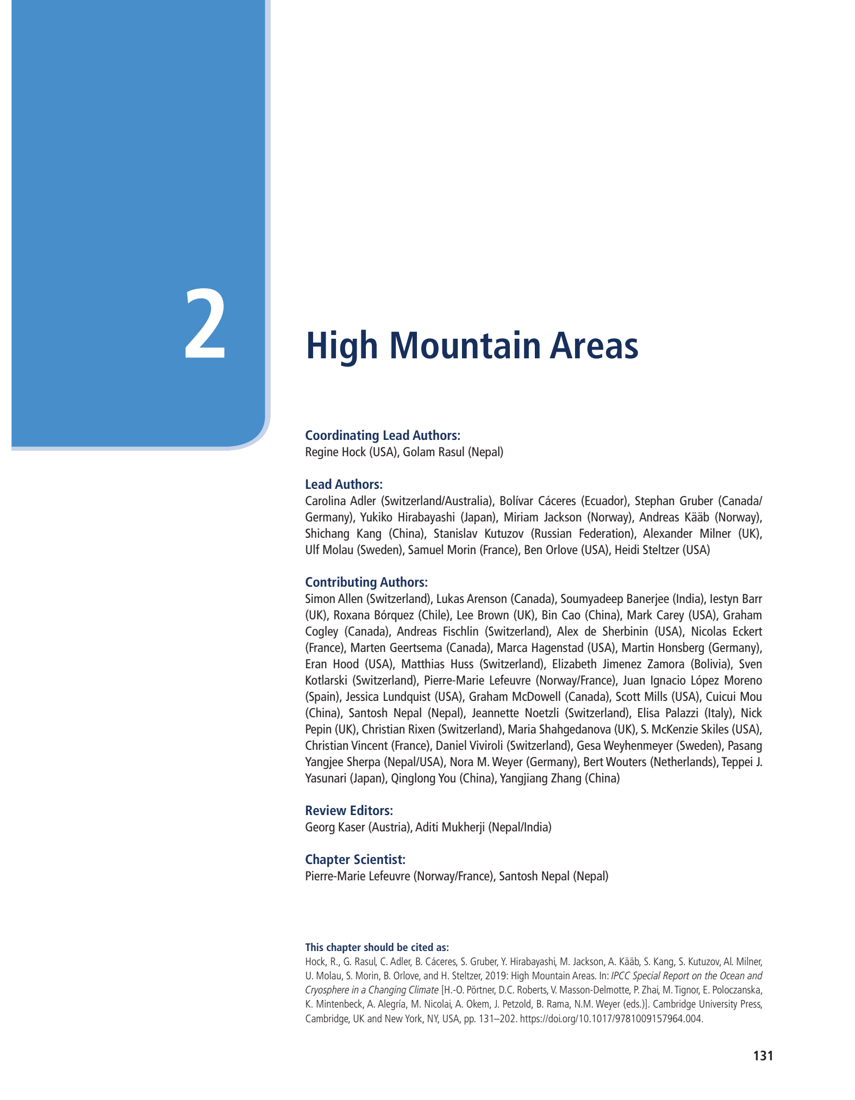

In [5]:
from PIL import Image
from IPython.display import display

from semanticlens.documents import PDFPageProcessor, DocumentsConfig

# Initialize our Documents module
processor = PDFPageProcessor(
    workspace=workspace,
    config=DocumentsConfig(),
)

# Process all pages of the PDF
units = list(processor.process(pdf_path))

# Verify results
assert units, "No pages were processed."
assert len(units) == units[0].document.page_count

print("PDF processing successful!")
print("Total pages processed:", len(units))

# Inspect first page
first_page = units[0]
image_path = workspace / first_page.image_ref

print("\nFirst page evidence:")
print("Document:", first_page.document.title)
print("Page:", first_page.page_number)
print("Unit ID:", first_page.unit_id)
print("Image exists:", image_path.is_file())

# Preview first rendered page
with Image.open(image_path) as image:
    preview = image.copy()
    preview.thumbnail((900, 1100))
    display(preview)


In [6]:
import torch

from semanticlens.core import Query
from semanticlens.embeddings import ColQwenConfig, ColQwenEmbedder

# ColQwen2 requires substantial GPU memory
if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU unavailable. Enable a GPU runtime in Colab before continuing."
    )

print("GPU:", torch.cuda.get_device_name(0))

# Configure our ColQwen2 adapter
embedder = ColQwenEmbedder(
    workspace=workspace,
    config=ColQwenConfig(
        device="cuda",
        dtype="float16",
        inference_batch_size=1,
    ),
)

print("Model:", embedder.spec.model_id)
print("Dimension:", embedder.spec.dimension)
print("Interaction:", embedder.spec.interaction)

# Test image embedding on the first PDF page
print("\nEncoding first PDF page...")
page_vectors = embedder.embed_units([units[0]])[0]

# Test text query embedding
print("Encoding text query...")
query_vectors = embedder.embed_query(
    Query(text="What are the main findings of this report?")
)

# Verify token-level embedding dimensions
assert len(page_vectors[0]) == embedder.spec.dimension
assert len(query_vectors[0]) == embedder.spec.dimension

print("\n✅ ColQwen2 embeddings generated successfully!")
print("Page embedding shape:", (len(page_vectors), len(page_vectors[0])))
print("Query embedding shape:", (len(query_vectors), len(query_vectors[0])))


GPU: Tesla T4
Model: vidore/colqwen2-v1.0-hf
Dimension: 128
Interaction: maxsim

Encoding first PDF page...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/6.08k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.42GB            

model.safetensors: downloading bytes:           |  0.00B            

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/613 [00:00<?, ?B/s]

Encoding text query...

✅ ColQwen2 embeddings generated successfully!
Page embedding shape: (755, 128)
Query embedding shape: (22, 128)


In [7]:
from semanticlens import SemanticLens
from semanticlens.indexes import QdrantConfig, QdrantVectorIndex
from semanticlens.retrieval import VectorRetriever
from semanticlens.evidence import SQLiteEvidenceResolver

# 1. Initialize Qdrant vector index
index = QdrantVectorIndex(
    spec=embedder.spec,
    config=QdrantConfig(
        path=workspace / "qdrant",
        collection_name="semanticlens_pages",
    ),
)

# 2. Initialize retrieval strategy
retriever = VectorRetriever()

# 3. Initialize persistent evidence storage
resolver = SQLiteEvidenceResolver(
    workspace=workspace,
)

# 4. Connect all components through Core
lens = SemanticLens(
    processor=processor,
    embedder=embedder,
    index=index,
    retriever=retriever,
    resolver=resolver,
    config=pipeline_config,
)

print("SemanticLens pipeline initialized!")
print("Embedding model:", lens._vector_index.spec.model_id)
print("Qdrant collection:", index.config.collection_name)
print("Evidence database:", resolver.database_path)
print("Ready to index:", pdf_path.name)


SemanticLens pipeline initialized!
Embedding model: vidore/colqwen2-v1.0-hf
Qdrant collection: semanticlens_pages
Evidence database: /content/lens_data/evidence/evidence.sqlite3
Ready to index: ipcc_report.pdf


In [8]:
from time import perf_counter

print(f"Indexing: {pdf_path.name}")
print(f"Total pages: {len(units)}")
print("This may take several minutes...\n")

start = perf_counter()

# Run the complete SemanticLens indexing pipeline
summary = lens.index(pdf_path)

elapsed = perf_counter() - start

# Verify indexing results
assert summary.documents_processed == 1
assert summary.units_indexed == len(units)

print("\n✅ Indexing completed successfully!")
print("Documents processed:", summary.documents_processed)
print("Pages indexed:", summary.units_indexed)
print("Pages skipped:", summary.units_skipped)
print(f"Time taken: {elapsed:.1f} seconds")


Indexing: ipcc_report.pdf
Total pages: 72
This may take several minutes...


✅ Indexing completed successfully!
Documents processed: 1
Pages indexed: 72
Pages skipped: 0
Time taken: 57.3 seconds


Question: Does Atmospheric Warming in the Mountains Depend on Elevation?
Results found: 3

Result #1
Document: ipcc_report
PDF page: 2
MaxSim score: 19.2677
Source: file:///content/pdf_uploads/ipcc_report.pdf


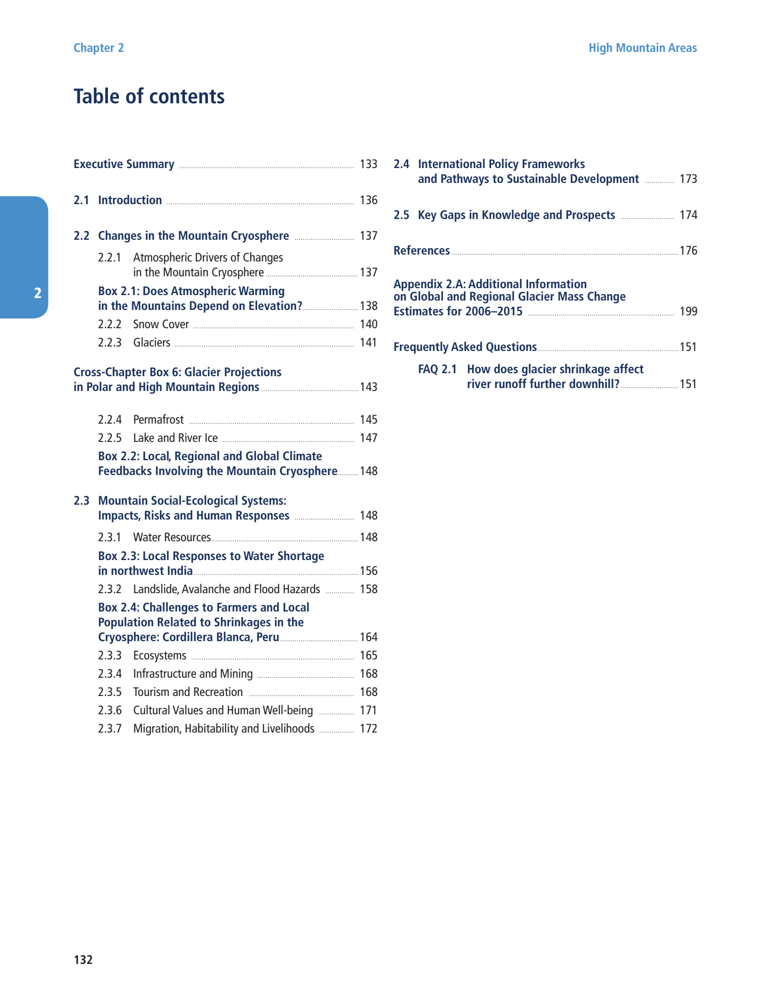


Result #2
Document: ipcc_report
PDF page: 8
MaxSim score: 19.1633
Source: file:///content/pdf_uploads/ipcc_report.pdf


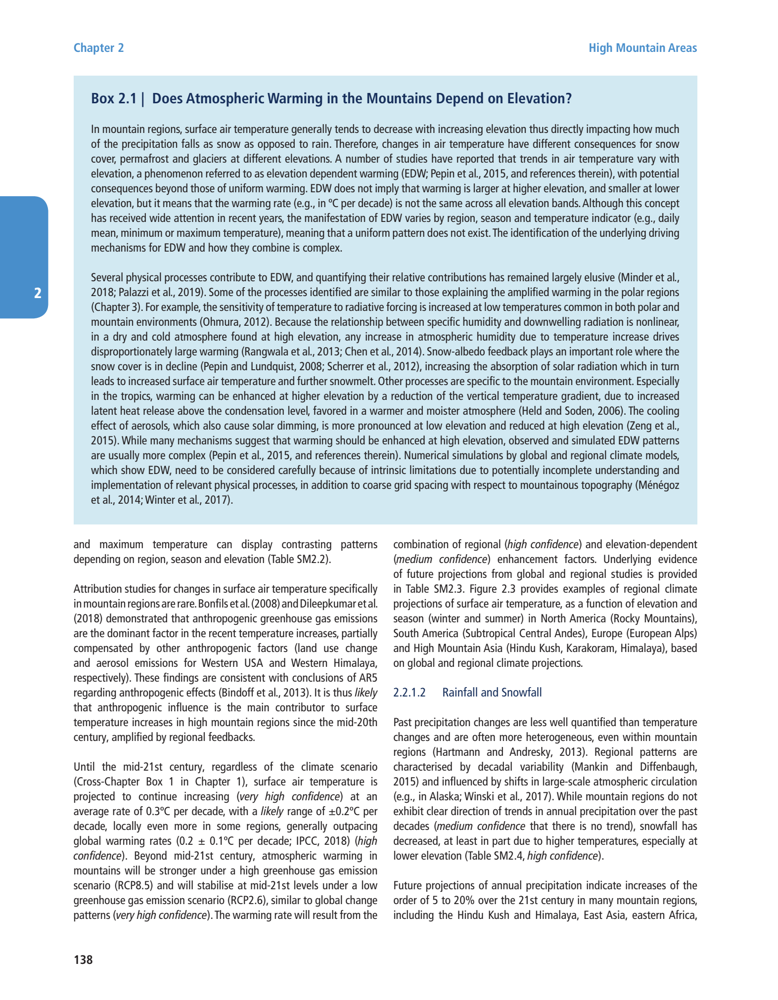


Result #3
Document: ipcc_report
PDF page: 9
MaxSim score: 17.6664
Source: file:///content/pdf_uploads/ipcc_report.pdf


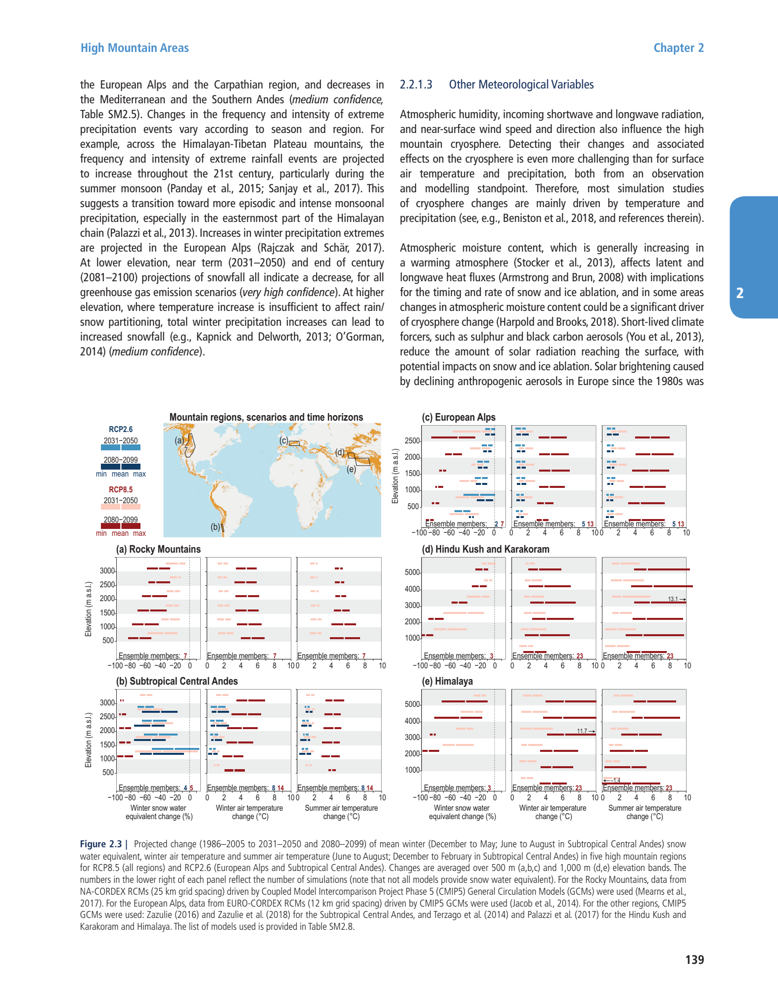

In [9]:
from pathlib import Path
from PIL import Image
from IPython.display import display

# Ask a question about your PDF
question = "Does Atmospheric Warming in the Mountains Depend on Elevation?"

# Search using the complete SemanticLens pipeline
hits = lens.search(question, top_k=3)

print("Question:", question)
print("Results found:", len(hits))

# Display retrieved evidence
for rank, hit in enumerate(hits, start=1):
    evidence = hit.evidence

    print(f"\n{'=' * 50}")
    print(f"Result #{rank}")
    print("Document:", evidence.document.title)
    print("PDF page:", evidence.page_number)
    print("MaxSim score:", round(hit.score, 4))
    print("Source:", evidence.document.source_uri)

    # Load the page image referenced by Evidence
    if evidence.image_ref:
        image_path = (workspace / evidence.image_ref).resolve()

        if not image_path.is_relative_to(workspace.resolve()):
            raise ValueError("Image path is outside the workspace")

        if not image_path.is_file():
            raise FileNotFoundError(image_path)

        with Image.open(image_path) as image:
            preview = image.copy()
            preview.thumbnail((800, 1000))
            display(preview)
